# Hyperparameter Tuning

In [1]:
import sys
sys.path.append('..')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import json

from src.utils import creating_datasets
from src.model import SimplestCNN
from src.train import train_one_epoch, validate

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cpu')

## Load Data

In [2]:
train_dataset, val_dataset, test_dataset = creating_datasets(
    root_dir='../data/raw',
    test_size=0.2,
    val_size=0.1,
    random_state=42
)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Training samples: 1531
Validation samples: 219
Test samples: 438


## Define Hyperparameter Grid

In [3]:
hyperparameter_grid = {
    'learning_rate': [0.0001, 0.001, 0.01],
    'batch_size': [32, 64, 128],
    'dropout_rate': [0.3, 0.5, 0.7]
}

## Grid Search Implementation

In [4]:
def train_with_hyperparameters(train_dataset, val_dataset, learning_rate, batch_size, dropout_rate, num_epochs=10):
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    model = SimplestCNN(num_classes=3, dropout_rate=dropout_rate).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    best_val_accuracy = 0.0
    
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_accuracy = validate(model, val_loader, criterion, device)
        
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
    
    return best_val_accuracy

## Run Grid Search

In [5]:
results = []
combinations = list(product(
    hyperparameter_grid['learning_rate'],
    hyperparameter_grid['batch_size'],
    hyperparameter_grid['dropout_rate']
))


for idx, (lr, bs, dr) in enumerate(combinations, 1):
    
    val_accuracy = train_with_hyperparameters(
        train_dataset=train_dataset,
        val_dataset=val_dataset,
        learning_rate=lr,
        batch_size=bs,
        dropout_rate=dr,
        num_epochs=10
    )
    
    results.append({
        'learning_rate': lr,
        'batch_size': bs,
        'dropout_rate': dr,
        'val_accuracy': val_accuracy
    })
    

## Results Analysis

In [6]:
results_df = pd.DataFrame(results).sort_values('val_accuracy', ascending=False)

print(results_df.head(5).to_string(index=False))

best_config = results_df.iloc[0]
print(f"Learning Rate: {best_config['learning_rate']}")
print(f"Batch Size: {int(best_config['batch_size'])}")
print(f"Dropout Rate: {best_config['dropout_rate']}")
print(f"Validation Accuracy: {best_config['val_accuracy']:.4f}")

 learning_rate  batch_size  dropout_rate  val_accuracy
         0.001          64           0.5      0.977169
         0.001          64           0.3      0.972603
         0.001          32           0.5      0.972603
         0.001          64           0.7      0.972603
         0.001          32           0.7      0.968037
Learning Rate: 0.001
Batch Size: 64
Dropout Rate: 0.5
Validation Accuracy: 0.9772


## Visualization

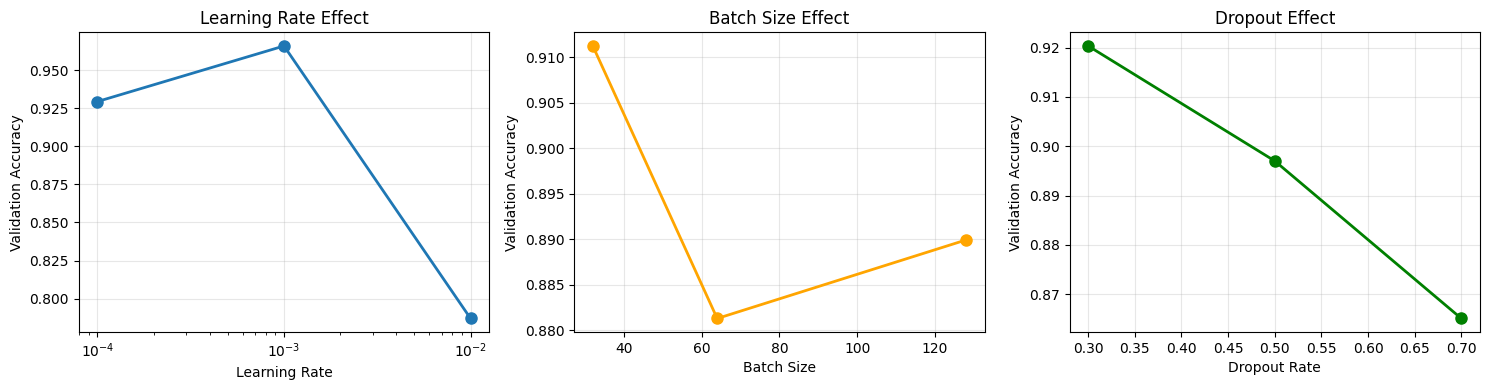

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

lr_grouped = results_df.groupby('learning_rate')['val_accuracy'].mean()
axes[0].plot(lr_grouped.index, lr_grouped.values, marker='o', linewidth=2, markersize=8)
axes[0].set_xlabel('Learning Rate')
axes[0].set_ylabel('Validation Accuracy')
axes[0].set_title('Learning Rate Effect')
axes[0].set_xscale('log')
axes[0].grid(alpha=0.3)

bs_grouped = results_df.groupby('batch_size')['val_accuracy'].mean()
axes[1].plot(bs_grouped.index, bs_grouped.values, marker='o', linewidth=2, markersize=8, color='orange')
axes[1].set_xlabel('Batch Size')
axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('Batch Size Effect')
axes[1].grid(alpha=0.3)

dr_grouped = results_df.groupby('dropout_rate')['val_accuracy'].mean()
axes[2].plot(dr_grouped.index, dr_grouped.values, marker='o', linewidth=2, markersize=8, color='green')
axes[2].set_xlabel('Dropout Rate')
axes[2].set_ylabel('Validation Accuracy')
axes[2].set_title('Dropout Effect')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/hyperparameter_effects.png', dpi=300, bbox_inches='tight')
plt.show()

## Save Results

In [8]:
results_df.to_csv('../reports/hyperparameter_tuning_results.csv', index=False)

best_hyperparameters = {
    'learning_rate': float(best_config['learning_rate']),
    'batch_size': int(best_config['batch_size']),
    'dropout_rate': float(best_config['dropout_rate']),
    'val_accuracy': float(best_config['val_accuracy'])
}

with open('../models/best_hyperparameters.json', 'w') as f:
    json.dump(best_hyperparameters, f, indent=4)